# NLP, TP 2 : préparer les répliques pour un réseau de neurones

Tâche suivie dans toute la série : à partir d'une réplique de *Tiny Shakespeare*, retrouver le personnage qui la prononce.

Ce notebook prépare les données côté deep learning :

1. charger le corpus et le découper en répliques étiquetées par leur locuteur ;
2. fixer la tâche (combien de personnages, quelles répliques garder) ;
3. faire un split stratifié train / validation / test (70 / 15 / 15) ;
4. construire un vocabulaire de mots à partir du train, puis un Dataset et des DataLoader PyTorch qui renvoient des séquences de longueur fixe.

## 1. Environnement

In [1]:
import re
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
pd.set_option("display.width", 120)

## 2. Le corpus

Même fichier que dans les TP Transformers, mais on ne travaille plus caractère par caractère : on veut des répliques entières.

In [2]:
URL_CORPUS = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
corpus = urllib.request.urlopen(URL_CORPUS).read().decode("utf-8")


def extraire_repliques(texte: str) -> pd.DataFrame:
    """Coupe le texte en blocs séparés par une ligne vide et garde ceux qui commencent par 'NOM:'."""
    lignes = []
    for bloc in texte.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        premiere, *suite = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", premiere)
        if entete and suite:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(l.strip() for l in suite).strip(),
            })
    return pd.DataFrame(lignes)


print(f"{len(corpus):,} caractères sur {len(corpus.splitlines()):,} lignes\n")
print(corpus[:300])

1,115,394 caractères sur 40,000 lignes

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 3. Étiqueter les répliques

Dans le fichier, une réplique est un bloc qui commence par une ligne NOM: suivie du texte. extraire_repliques (définie juste au-dessus) produit un tableau à deux colonnes : locuteur et replique.

In [3]:
repliques = extraire_repliques(corpus)

print(f"{len(repliques):,} répliques, {repliques['locuteur'].nunique()} locuteurs différents")
repliques.head(10)

7,094 répliques, 297 locuteurs différents


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


## 4. Définir la tâche

Avec presque 300 locuteurs, la plupart n'ont que quelques répliques. On restreint donc le problème :

| Choix | Valeur | Raison |
|---|---|---|
| Nombre de personnages | 5 (les plus bavards) | des effectifs comparables, de 126 à 196 répliques, et une matrice de confusion 5 × 5 qu'on peut lire à l'œil |
| Longueur minimale | 5 mots | une réplique du type « Ay, my lord » ne dit rien sur celui qui parle, c'est du bruit |
| Taille obtenue | environ 760 répliques | peu, mais assez pour un modèle linéaire creux et pour comparer des approches |

In [4]:
N_LOCUTEURS = 5
MIN_MOTS = 5

repliques["n_mots"] = repliques["replique"].str.split().str.len()
top_locuteurs = repliques["locuteur"].value_counts().head(N_LOCUTEURS).index

garde = repliques["locuteur"].isin(top_locuteurs) & (repliques["n_mots"] >= MIN_MOTS)
donnees = repliques.loc[garde, ["replique", "locuteur"]].reset_index(drop=True)

effectifs = donnees["locuteur"].value_counts()
print(effectifs.to_string(), "\n")
print(f"{len(donnees)} répliques gardées")
print(f"rapport classe la plus grande / la plus petite : {effectifs.max() / effectifs.min():.2f}")
print(f"part de la classe majoritaire : {effectifs.max() / len(donnees):.1%} (accuracy qu'on obtient en répondant toujours la même chose)")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126 

761 répliques gardées
rapport classe la plus grande / la plus petite : 1.56
part de la classe majoritaire : 25.8% (accuracy qu'on obtient en répondant toujours la même chose)


## 5. Split train / validation / test

On procède en deux temps : 70 % pour le train, puis le reste coupé en deux moitiés (15 % validation, 15 % test). Le paramètre stratify garde les mêmes proportions de personnages dans les trois parties, ce qui compte puisque les classes ne sont pas équilibrées.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    donnees["replique"], donnees["locuteur"],
    test_size=0.30, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE,
)

print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)}\n")
proportions = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "val": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
print(proportions)

train 532 | val 114 | test 115

                train    val   test
locuteur                           
GLOUCESTER      0.258  0.254  0.261
DUKE VINCENTIO  0.216  0.219  0.217
ROMEO           0.186  0.184  0.183
PETRUCHIO       0.175  0.175  0.174
MENENIUS        0.165  0.167  0.165


## 6. Des répliques aux séquences d'indices

Un réseau de neurones attend des tenseurs de taille fixe. Il faut donc :

1. découper chaque réplique en mots (tokenisation) ;
2. associer un indice à chaque mot, avec un vocabulaire construit sur le train seulement pour éviter toute fuite d'information ;
3. ramener chaque séquence à T_MAX_LEN indices, en tronquant les longues et en complétant les courtes avec [PAD].

### 6.1 Tokenisation et choix de T_MAX_LEN

La tokenisation reste volontairement simple : passage en minuscules, ponctuation . , ! ? séparée des mots. Pour choisir la longueur maximale, on regarde la distribution du nombre de tokens par réplique dans le train.

quantiles du nombre de tokens (train) :
0.50     22.50
0.75     49.25
0.90     88.90
0.95    132.45

part des répliques de 40 tokens ou moins : 68.6%


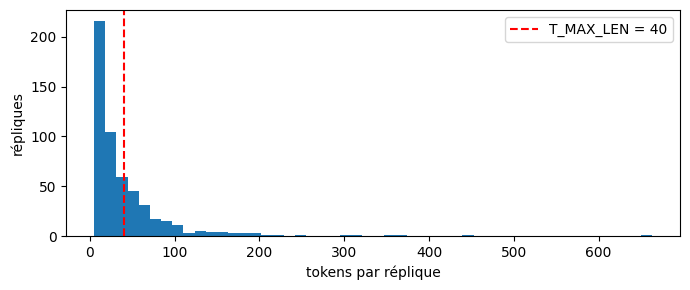

In [6]:
def tokeniser(texte):
    texte = texte.lower()
    texte = re.sub(r"([.,!?])", r" \1 ", texte)
    return texte.split()


longueurs = X_train.map(lambda r: len(tokeniser(r)))
print("quantiles du nombre de tokens (train) :")
print(longueurs.quantile([0.5, 0.75, 0.9, 0.95]).to_string())
print(f"\npart des répliques de 40 tokens ou moins : {(longueurs <= 40).mean():.1%}")

plt.figure(figsize=(7, 3))
plt.hist(longueurs, bins=50)
plt.axvline(40, color="red", ls="--", label="T_MAX_LEN = 40")
plt.xlabel("tokens par réplique"); plt.ylabel("répliques"); plt.legend()
plt.tight_layout(); plt.show()

On retient T_MAX_LEN = 40. La médiane est autour de 22 tokens et 40 tokens couvrent environ deux tiers des répliques (pourcentage exact affiché au-dessus). Les répliques plus longues sont tronquées : on garde leurs 40 premiers tokens, ce qui suffit en général à reconnaître le style. Prendre la longueur maximale (plusieurs centaines de tokens) obligerait à remplir presque toutes les séquences avec du padding.

### 6.2 Vocabulaire (train uniquement)

Comme le min_df=2 du TF-IDF du TP 1, on ne garde que les mots vus au moins deux fois dans le train. Deux indices sont réservés : 0 pour [PAD] et 1 pour [UNK] (mot absent du vocabulaire).

In [7]:
T_MAX_LEN = 40
FREQ_MIN = 2

freq_mots = Counter(tok for replique in X_train for tok in tokeniser(replique))

vocab = {"[PAD]": 0, "[UNK]": 1}
for mot, freq in freq_mots.items():
    if freq >= FREQ_MIN:
        vocab[mot] = len(vocab)

print(f"taille du vocabulaire : {len(vocab):,}")

taille du vocabulaire : 1,427


### 6.3 Dataset et DataLoader

Le Dataset renvoie, pour chaque réplique, un tenseur de T_MAX_LEN indices et l'identifiant du personnage. Les personnages sont numérotés de 0 à 4 dans l'ordre alphabétique.

In [8]:
class RepliquesDataset(Dataset):

    def __init__(self, X, y, vocab, classe_vers_id, max_len=T_MAX_LEN):
        self.textes = list(X)
        self.labels = [classe_vers_id[nom] for nom in y]
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.textes)

    def encoder(self, texte):
        ids = [self.vocab.get(tok, self.vocab["[UNK]"]) for tok in tokeniser(texte)]
        ids = ids[:self.max_len]                                       # troncature
        return ids + [self.vocab["[PAD]"]] * (self.max_len - len(ids))  # padding

    def __getitem__(self, i):
        return (torch.tensor(self.encoder(self.textes[i]), dtype=torch.long),
                torch.tensor(self.labels[i], dtype=torch.long))


classe_vers_id = {nom: i for i, nom in enumerate(sorted(y_train.unique()))}
print("classes :", classe_vers_id)

train_ds = RepliquesDataset(X_train, y_train, vocab, classe_vers_id)
val_ds = RepliquesDataset(X_val, y_val, vocab, classe_vers_id)
test_ds = RepliquesDataset(X_test, y_test, vocab, classe_vers_id)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

classes : {'DUKE VINCENTIO': 0, 'GLOUCESTER': 1, 'MENENIUS': 2, 'PETRUCHIO': 3, 'ROMEO': 4}


Contrôle sur un batch : on attend (32, 40) pour les entrées et (32,) pour les étiquettes. On décode aussi la première séquence pour voir le résultat de la tokenisation, des [UNK] et du padding.

In [9]:
xb, yb = next(iter(train_loader))
print("entrées :", tuple(xb.shape), "| étiquettes :", tuple(yb.shape))

id_vers_mot = {i: m for m, i in vocab.items()}
id_vers_classe = {i: nom for nom, i in classe_vers_id.items()}
print("\nexemple décodé :", " ".join(id_vers_mot[i] for i in xb[0].tolist()))
print("personnage    :", id_vers_classe[yb[0].item()])

entrées : (32, 40) | étiquettes : (32,)

exemple décodé : signior hortensio , 'twixt such friends as we few words [UNK] and therefore , if thou know one rich enough to be [UNK] wife , as [UNK] is burden of my [UNK] [UNK] , be she as [UNK] as was
personnage    : PETRUCHIO
